This notebook is dedicated to the analysis of the CSV results

In [3]:
# first we need to import our visualization libraries and any other related components

import json # need to parse geojson
import re # needed for wordcloud example

import matplotlib.pyplot as plt # 
import pandas as pd # using data frames with our plotly visualization
import plotly.express as px # px shorthand is used in plotly examples
import pydeck as pdk # pdk is used as a shorthand for pydeck examples

from IPython.display import HTML, IFrame # needed to display pydeck visualization in the notebook
from wordcloud import STOPWORDS, wordcloud #

Matplotlib is building the font cache; this may take a moment.


In [2]:
%pip install matplotlib pandas plotly pydeck wordcloud

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 46.0 MB/s  0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 34.7 MB/s  0:00:0032.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 36.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 43.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [wordcloud]━ 7/9 [matplotlib]ck]
Note: you may need to restart the kernel to use updated packages.


In [4]:
nativeamerican = pd.read_csv("artworks_combined_3.csv")

nativeamerican.head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,classification,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
0,120950,False,1976.55,1976.0,True,https://images.metmuseum.org/CRDImages/ao/orig...,https://images.metmuseum.org/CRDImages/ao/web-...,[],NaN,The Michael C. Rockefeller Wing,...,Feathers-Costumes,NaN,NaN,2026-10-21T04:58:17.613Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
1,27229,False,1978.132.2,1978.0,False,NaN,NaN,[],NaN,Arms and Armor,...,Shafted Weapons,NaN,NaN,2025-03-06T04:54:30Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
2,500882,False,89.4.3560,1889.0,False,NaN,NaN,[],NaN,Musical Instruments,...,Aerophone-Blow Hole-side-blown flute (transverse),NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
3,500888,False,06.1257,1906.0,False,NaN,NaN,[],NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
4,500889,False,06.1258,1906.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116412906,False,NaN


In [5]:
pd.set_option('display.max_rows', None)

nativeamerican['state'].value_counts()

state
British Columbia                               159
Nunavut                                        128
Oklahoma                                       124
Alaska                                          91
Arizona                                         84
Arizona or New Mexico                           52
New Mexico                                      43
California                                      32
Quebec                                          19
New York                                        12
Demerara                                        12
Minnesota                                        9
New Brunswick or Nova Scotia                     8
South Dakota                                     7
Washington                                       7
North Dakota or South Dakota                     6
Ontario                                          5
Wyoming                                          4
Florida                                          4
Maine                    

In [7]:
nativeamerican_with_state = pd.read_csv("artworks_combined_3_with_state.csv")

#preview what's in each file:
nativeamerican_with_state.head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,classification,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
0,500888,False,06.1257,1906.0,False,NaN,NaN,[],NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
1,500889,False,06.1258,1906.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116412906,False,NaN
2,501178,False,"89.4.562a, b",1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,"[{'constituentID': 155406, 'role': 'Maker', 'n...",Musical Instruments,...,Membranophone-single-headed / frame drum,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
3,501180,False,89.4.564,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Chordophone-Lute,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
4,501189,False,89.4.573,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Aerophone-Blow Hole-end-blown flute (vertical),NaN,NaN,2024-05-17T04:51:53.097Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN


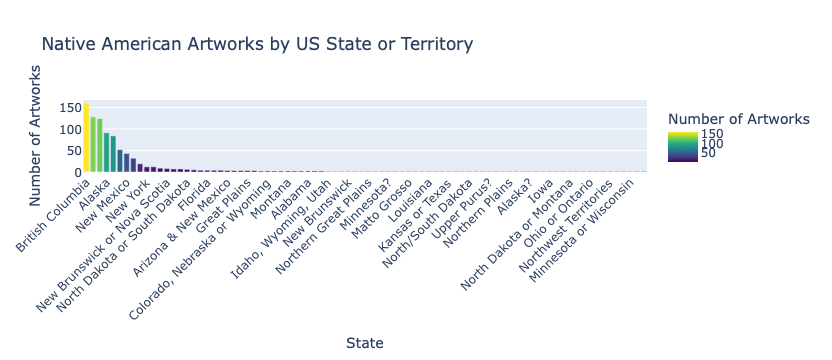

In [9]:
state_counts = nativeamerican_with_state["state"].value_counts().reset_index()

state_counts.columns = ["state", "artwork_count"]

# Create bar graph
fig = px.bar(
    state_counts,
    x="state",
    y="artwork_count",
    title="Native American Artworks by US State or Territory",
    labels={
        "state": "State",
        "artwork_count": "Number of Artworks"
    },
    color="artwork_count",
    color_continuous_scale="Viridis"
)

fig.update_layout(
    autosize=True,
    width=None,
    xaxis_title="State",
    yaxis_title="Number of Artworks",
    xaxis_tickangle=-45,
    xaxis={"categoryorder": "total descending"}
)

fig.show()

In [10]:
native_with_state_filtered = pd.read_csv("artworks_combined_3_with_state_cleaned.csv")

#preview what's in each file:
native_with_state_filtered.head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,classification,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
0,500888,False,06.1257,1906.0,False,NaN,NaN,[],NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
1,500889,False,06.1258,1906.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116412906,False,NaN
2,501180,False,89.4.564,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Chordophone-Lute,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
3,501197,False,89.4.581,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
4,501200,False,89.4.584,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Struck-bell-clapper,NaN,NaN,2024-03-22T04:53:07.663Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN


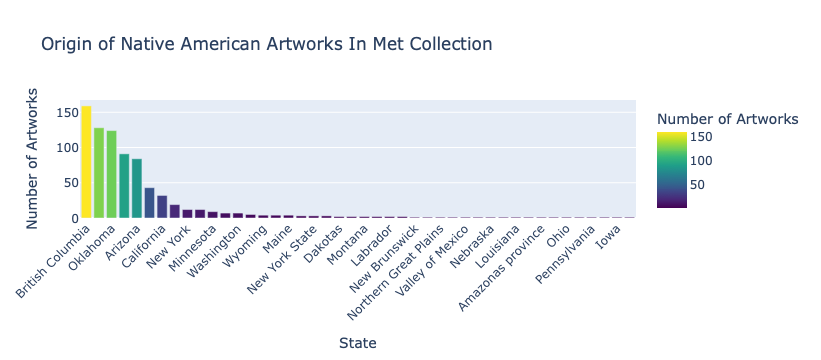

In [11]:
state_counts = native_with_state_filtered["state"].value_counts().reset_index()

state_counts.columns = ["state", "artwork_count"]

# Create bar graph
fig = px.bar(
    state_counts,
    x="state",
    y="artwork_count",
    title="Origin of Native American Artworks In Met Collection",
    labels={
        "state": "State",
        "artwork_count": "Number of Artworks"
    },
    color="artwork_count",
    color_continuous_scale="Viridis"
)

fig.update_layout(
    autosize=True,
    width=None,
    xaxis_title="State",
    yaxis_title="Number of Artworks",
    xaxis_tickangle=-45,
    xaxis={"categoryorder": "total descending"}
)

fig.show()

In [12]:
pip install wordcloud matplotlib

Note: you may need to restart the kernel to use updated packages.


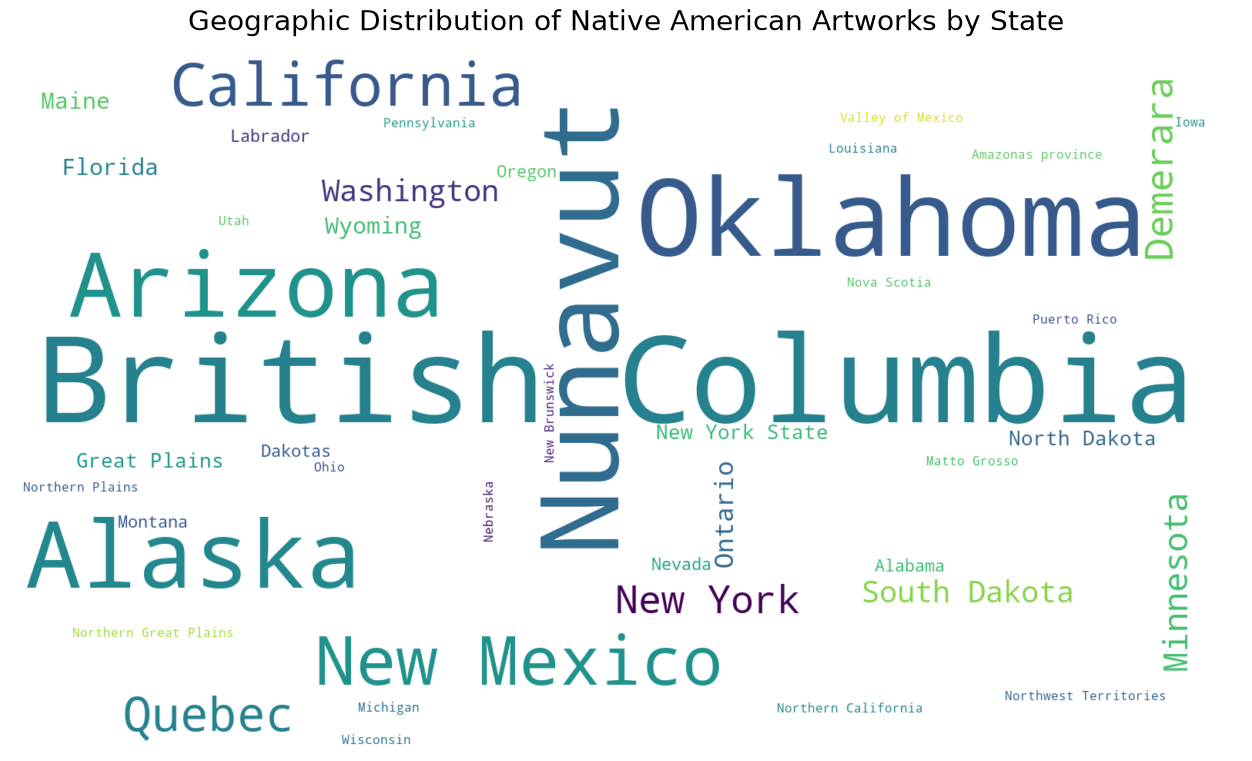

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Read your CSV
df = pd.read_csv("artworks_combined_3_with_state_cleaned.csv")

# Calculate the frequency of each state
state_counts = df["state"].dropna().value_counts()

# Convert counts into a dictionary
state_freq = state_counts.to_dict()

# Generate the word cloud
wordcloud = WordCloud(
    width=1600,
    height=900,
    background_color="white",
    colormap="viridis",
    prefer_horizontal=0.9,
    max_words=100
).generate_from_frequencies(state_freq)

# Display the word cloud
plt.figure(figsize=(16, 9))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Geographic Distribution of Native American Artworks by State",
          fontsize=20, pad=20)

plt.show()

# Save as PNG
wordcloud.to_file("state_wordcloud.png")

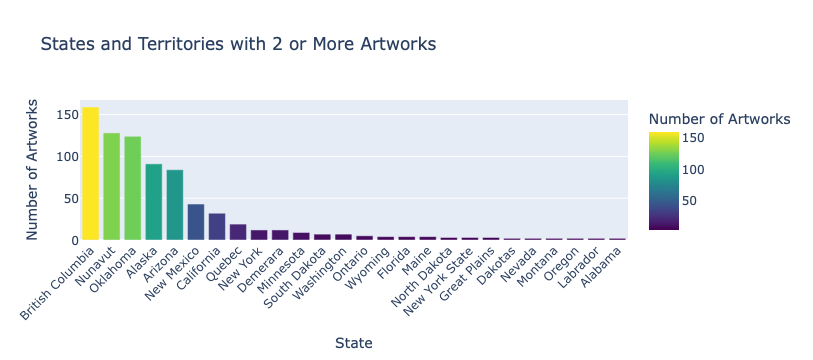

AttributeError: 'Figure' object has no attribute 'to_file'

In [15]:
# Count artworks by state
state_counts = native_with_state_filtered["state"].value_counts().reset_index()

state_counts.columns = ["state", "artwork_count"]

# Remove states with only 1 artwork
state_counts = state_counts[state_counts["artwork_count"] > 1] # added to make chart more readable

# Create bar graph
fig = px.bar(
    state_counts,
    x="state",
    y="artwork_count",
    title="States and Territories with 2 or More Artworks",
    labels={
        "state": "State or Territory",
        "artwork_count": "Number of Artworks"
    },
    color="artwork_count",
    color_continuous_scale="Viridis"
)

fig.update_layout(
    autosize=True,
    width=None,
    xaxis_title="State",
    yaxis_title="Number of Artworks",
    xaxis_tickangle=-45,
    xaxis={"categoryorder": "total descending"}
)

fig.show()
fig.to_file("state_bargraph.png")